# Conversion funnel and friction analysis (SQL)

FormWise is a made-up online legal-document subscription service. The data is simulated (see `data/generate_data.py`).

Overall conversion from visit to paid subscription is about 5%. Where are people dropping off, and which fix is
worth the most?

All the metrics are written in SQL (the `sql/` folder). Python is only used for charts and for things SQLite
can't do, like medians and chi-square tests.

Two choices worth noting:
- Funnel steps count **distinct visitors**, so duplicate events can't inflate a step.
- Purchases come from the billing tables (`subscriptions`), not the front-end `purchase` event. The event has
  known gaps (duplicates, missing user IDs from one app release).

In [1]:
import os, sys, sqlite3, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DB = "data/formwise.db"
if not os.path.exists(DB):
    subprocess.run([sys.executable, "data/generate_data.py"], check=True)
con = sqlite3.connect(DB)

def q(sql):
    if sql.endswith(".sql"):
        sql = open(sql).read()
    return pd.read_sql_query(sql, con)

BLUE, ORANGE, GREY = "#2B5C8A", "#D9822B", "#9AA5B1"
plt.rcParams.update({"figure.figsize": (9, 4.5), "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
os.makedirs("figures", exist_ok=True)
pct = plt.FuncFormatter(lambda v, _: f"{v:.0%}")
from scipy import stats

## 1. Overall funnel

In [2]:
f = q("sql/01_overall_funnel.sql")
f["step_conversion"] = f.visitors / f.visitors.shift(1)
f["of_landing"] = f.visitors / f.visitors.iloc[0]
f["lost_at_step"] = f.visitors.shift(1) - f.visitors
print(f.round(4).to_string(index=False))

          step  step_order  visitors  step_conversion  of_landing  lost_at_step
  landing_view           1    180000              NaN      1.0000           NaN
template_start           2     83072           0.4615      0.4615       96928.0
 form_complete           3     47924           0.5769      0.2662       35148.0
  paywall_view           4     45561           0.9507      0.2531        2363.0
      purchase           5      8583           0.1884      0.0477       36978.0


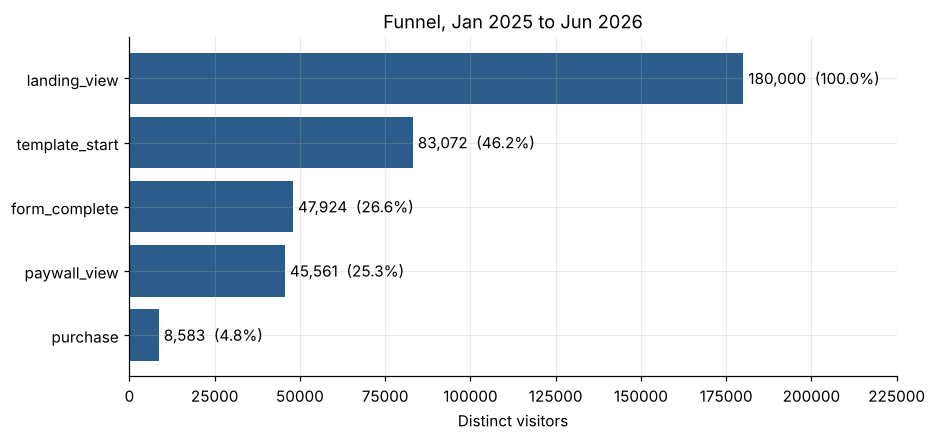

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(f.step[::-1], f.visitors[::-1], color=BLUE)
for i, (n, share) in enumerate(zip(f.visitors[::-1], f.of_landing[::-1])):
    ax.text(n + 1500, i, f"{n:,.0f}  ({share:.1%})", va="center")
ax.set_xlim(0, f.visitors.max() * 1.25); ax.set_xlabel("Distinct visitors")
ax.set_title("Funnel, Jan 2025 to Jun 2026")
fig.savefig("figures/overall_funnel.png", bbox_inches="tight", dpi=140); plt.show()

After the landing page, the two biggest losses are at the form (template start to form complete) and at the
paywall. Some landing bounce is normal for search traffic, and the paywall has its own A/B test, so I focused on
the form.

## 2. By device

In [4]:
d = q("sql/02_funnel_by_device.sql")
print(d.to_string(index=False))

 device  visitors  landing_to_start  start_to_complete  complete_to_paywall  paywall_to_purchase  overall_conversion
desktop     93552            0.5011             0.6444               0.9513               0.2131              0.0655
 mobile     73779            0.4103             0.4726               0.9493               0.1390              0.0256
 tablet     12669            0.4672             0.5758               0.9510               0.1762              0.0451


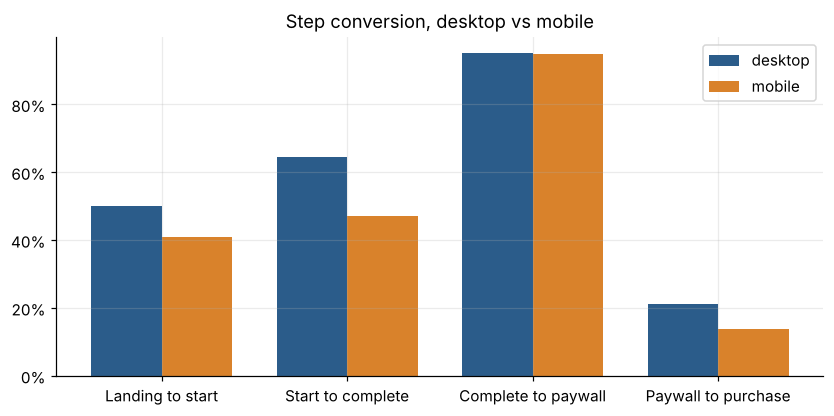

In [5]:
steps = ["landing_to_start", "start_to_complete", "complete_to_paywall", "paywall_to_purchase"]
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(steps)); w = 0.38
for i, dev in enumerate(["desktop", "mobile"]):
    ax.bar(x + (i - 0.5) * w, d.set_index("device").loc[dev, steps], w, label=dev, color=[BLUE, ORANGE][i])
ax.set_xticks(x, ["Landing to start", "Start to complete", "Complete to paywall", "Paywall to purchase"])
ax.yaxis.set_major_formatter(pct); ax.legend()
ax.set_title("Step conversion, desktop vs mobile")
fig.savefig("figures/step_conversion_by_device.png", bbox_inches="tight", dpi=140); plt.show()

In [6]:
dd = d.set_index("device")
gap = dd.loc["desktop", "start_to_complete"] - dd.loc["mobile", "start_to_complete"]
print(f"Mobile form completion is {gap:.1%} points lower than desktop "
      f"({dd.loc['mobile','start_to_complete']:.1%} vs {dd.loc['desktop','start_to_complete']:.1%}).")

Mobile form completion is 17.2% points lower than desktop (47.3% vs 64.4%).


Mobile is behind at every step, but the form step has the biggest gap. Before calling it, I wanted to check it
isn't noise and see whether it's the same for every document type.

## 3. Form completion by document type and device

In [7]:
fc = q("sql/03_form_completion_by_doc_and_device.sql")
piv = fc.pivot(index="doc_type", columns="device", values="completion_rate")
piv["gap_pts"] = piv.desktop - piv.mobile
cnt = fc.pivot(index="doc_type", columns="device", values=["starters", "completers"])
pvals = []
for doc in piv.index:
    table = [[cnt.loc[doc, ("completers", dv)], cnt.loc[doc, ("starters", dv)] - cnt.loc[doc, ("completers", dv)]]
             for dv in ["desktop", "mobile"]]
    pvals.append(stats.chi2_contingency(table)[1])
piv["p_value"] = pvals
out = piv.sort_values("gap_pts", ascending=False).round(4)
out["p_value"] = out.p_value.map(lambda p: "<0.001" if p < 0.001 else f"{p:.3f}")
print(out.to_string())

device             desktop  mobile  gap_pts p_value
doc_type                                           
bill_of_sale        0.6650  0.4834   0.1816  <0.001
will                0.5797  0.4029   0.1768  <0.001
nda                 0.6639  0.4877   0.1762  <0.001
lease_agreement     0.6604  0.4884   0.1720  <0.001
power_of_attorney   0.6519  0.4891   0.1628  <0.001
promissory_note     0.6586  0.5053   0.1533  <0.001


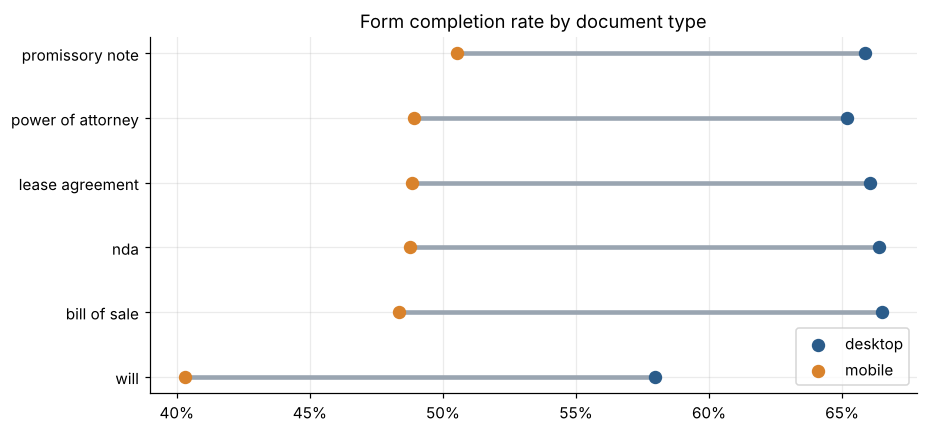

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.2))
order = piv.sort_values("mobile").index
y = np.arange(len(order))
ax.hlines(y, piv.loc[order, "mobile"], piv.loc[order, "desktop"], color=GREY, lw=3)
ax.scatter(piv.loc[order, "desktop"], y, color=BLUE, s=60, label="desktop", zorder=3)
ax.scatter(piv.loc[order, "mobile"], y, color=ORANGE, s=60, label="mobile", zorder=3)
ax.set_yticks(y, [o.replace("_", " ") for o in order])
ax.xaxis.set_major_formatter(pct); ax.legend(loc="lower right")
ax.set_title("Form completion rate by document type")
fig.savefig("figures/form_completion_by_doc.png", bbox_inches="tight", dpi=140); plt.show()

The gap is significant for every document type, so it's a mobile form problem in general rather than one bad
template. The will template is lowest on both devices, which fits with it being the longest form.

## 4. Time to complete

In [9]:
tt = q("sql/04_time_to_complete.sql")
med = tt.groupby(["doc_type", "device"]).minutes_to_complete.median().unstack().round(1)
print("Median minutes from template start to form complete:")
print(med.to_string())

Median minutes from template start to form complete:
device             desktop  mobile  tablet
doc_type                                  
bill_of_sale          21.8    21.5    22.5
lease_agreement       22.0    21.8    20.9
nda                   21.9    21.4    21.7
power_of_attorney     22.3    21.0    21.8
promissory_note       22.0    22.7    21.1
will                  22.4    22.5    22.6


Mobile users who finish take about the same time as desktop users. So the issue is people giving up, not people
being slow. My guess is that mobile sessions get interrupted and it's hard to come back to a half-filled form, but
the current data can't confirm that. We'd need field-level events (which field people leave on) to know.

## 5. Monthly trend and channels

In [10]:
m = q("sql/05_monthly_trend.sql")
print(m.to_string(index=False))

  month  visitors  purchases  conversion  conversion_mom_change  cumulative_purchases  conversion_3mo_avg
2025-01      7971        389      0.0488                    NaN                   389              0.0488
2025-02      7425        363      0.0489                 0.0001                   752              0.0488
2025-03      8318        376      0.0452                -0.0037                  1128              0.0476
2025-04      8586        383      0.0446                -0.0006                  1511              0.0462
2025-05      8851        421      0.0476                 0.0030                  1932              0.0458
2025-06      8895        393      0.0442                -0.0034                  2325              0.0455
2025-07      9633        465      0.0483                 0.0041                  2790              0.0467
2025-08      9757        438      0.0449                -0.0034                  3228              0.0458
2025-09      9895        474      0.0479      

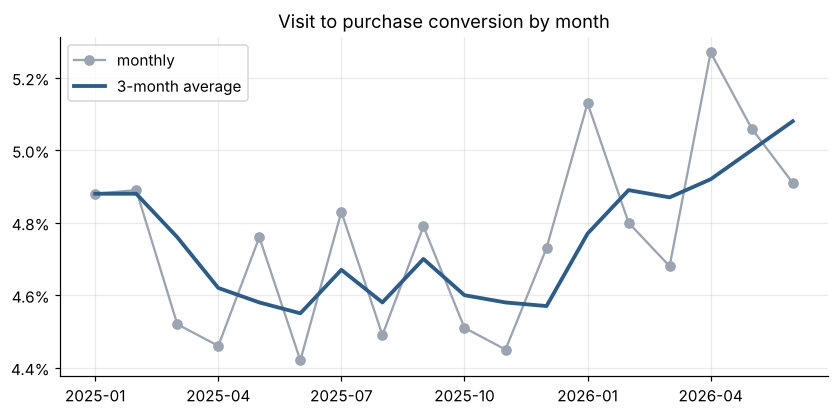

In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(m.month, m.conversion, marker="o", color=GREY, label="monthly")
ax.plot(m.month, m.conversion_3mo_avg, color=BLUE, lw=2.5, label="3-month average")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}")); ax.legend()
ax.set_xticks(m.month[::3]); ax.set_title("Visit to purchase conversion by month")
fig.savefig("figures/monthly_conversion.png", bbox_inches="tight", dpi=140); plt.show()

In [12]:
ch = q("sql/06_channel_performance.sql")
print(ch.to_string(index=False))

       channel  visitors  purchases  conversion  first_payment_revenue  revenue_per_visitor
   paid_search     39772       2347      0.0590              144995.88                3.646
         email     14332        798      0.0557               48567.24                3.389
        direct     26972       1254      0.0465               78316.02                2.904
organic_search     68407       3165      0.0463              194418.81                2.842
      referral      8862        387      0.0437               24027.30                2.711
        social     21655        632      0.0292               38854.95                1.794


## 6. What is fixing the mobile form worth?
Rough sizing: mobile form completion closes half the gap to desktop, and every later step stays at today's mobile
rate.

In [13]:
mob = dd.loc["mobile"]
monthly_mobile_visitors = mob.visitors / len(m)
target = mob.start_to_complete + gap / 2
now = monthly_mobile_visitors * mob.landing_to_start * mob.start_to_complete * mob.complete_to_paywall * mob.paywall_to_purchase
new = monthly_mobile_visitors * mob.landing_to_start * target * mob.complete_to_paywall * mob.paywall_to_purchase
avg_first = q("SELECT AVG(amount) AS a FROM payments WHERE payment_type = 'new'").a[0]
print(f"Mobile purchases per month now: {now:,.0f}")
print(f"With half the gap closed: {new:,.0f}  (+{new-now:,.0f}/month, +{new/now-1:.0%})")
print(f"Extra first-payment revenue: about ${(new-now)*avg_first:,.0f}/month, ${(new-now)*avg_first*12:,.0f}/year "
      f"before renewals (avg first payment ${avg_first:.2f})")

Mobile purchases per month now: 105
With half the gap closed: 124  (+19/month, +18%)
Extra first-payment revenue: about $1,175/month, $14,103/year before renewals (avg first payment $61.65)


## 7. Recommendations
1. Make the mobile form the main funnel priority. It loses more mobile users than the paywall does, and the gap
   shows up for every template.
2. Add tracking before redesigning: a `form_field_error` event and a `form_abandon` event with the last field
   completed.
3. Test save-and-resume on mobile (for example, email a link to finish later), starting with the will template.
4. Report funnels on distinct visitors and billing-confirmed purchases rather than raw event counts.

In [14]:
con.close()